# Compare observing strategies

Should a transient survey cover a large area shallowly, or stare at a few fields more deeply and more often?
In this example we build three mock surveys that share **the same number of exposures** but spend them differently,
observe the same simulated universe of Type Ia supernovae (SNe Ia) with each of them, and compare what comes out:
how many well-sampled lightcurves, up to which redshift, and how well the rise to peak is covered.

:::{note}
This page assumes you know the basics of {class}`skysurvey.GridSurvey`, {class}`skysurvey.SNeIa` and
{class}`skysurvey.DataSet` (see the [quickstart](../quickstart/index.rst)).
:::

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from shapely import geometry

import skysurvey

## Define the fields

We use a {class}`skysurvey.GridSurvey`: the telescope points at pre-defined **fields**, each covered by a
square $3\times3$ deg$^2$ camera footprint. The fields tile a $6\times6$ grid around the celestial equator
(about 325 deg$^2$ in total). The deep strategy will only use the 12 central fields.

In [2]:
footprint = geometry.box(-1.5, -1.5, 1.5, 1.5)  # 3x3 deg camera, centered on (0, 0)

ra_centers = 1.5 + 3 * np.arange(6)    # 1.5 ... 16.5 deg
dec_centers = -7.5 + 3 * np.arange(6)  # -7.5 ... 7.5 deg
fields = {f"F{i}{j}": {"ra": ra, "dec": dec}
          for i, ra in enumerate(ra_centers)
          for j, dec in enumerate(dec_centers)}

deep_fields = [name for name in fields if 1 <= int(name[1]) <= 4 and 2 <= int(name[2]) <= 4]
len(fields), len(deep_fields)

(36, 12)

## Write three observing logs

An observing log is a table with one row per exposure and (at least) the columns `fieldid`, `mjd`, `band`,
`skynoise`, `gain` and `zp`. The small helper below observes each field every `cadence` days during 180 days,
taking one exposure per band on each visit.

`skynoise` is the background noise of an exposure (in flux units of the zero point `zp`). The 5$\sigma$ limiting
magnitude of an exposure is roughly $m_\mathrm{lim} = \mathrm{zp} - 2.5\log_{10}(5\times\mathrm{skynoise})$, so
halving `skynoise` goes 0.75 mag deeper.

In [3]:
rng = np.random.default_rng(42)
MJD_START, DURATION = 60_000, 180  # survey start (mjd) and duration (days)

def make_logs(fieldids, cadence, bands, skynoise, zp=30):
    nights = MJD_START + np.arange(0, DURATION, cadence)
    fid, night, band = (a.ravel() for a in np.meshgrid(fieldids, nights, bands, indexing="ij"))
    mjd = night + rng.uniform(0.1, 0.4, size=len(night))  # visit time within the night
    noise = rng.normal(skynoise, 0.1 * skynoise, size=len(night))  # varying conditions
    return pd.DataFrame({"fieldid": fid, "mjd": mjd, "band": band,
                         "skynoise": noise, "gain": 1, "zp": zp})

The three strategies all use 6480 exposures:

- **wide**: the 36 fields, every 3 days, in $g, r, i$, with `skynoise=200` (depth $\approx 22.5$ mag);
- **deep**: the 12 central fields, every day, in $g, r, i$, with `skynoise=100` (depth $\approx 23.3$ mag);
- **wide-gr**: the 36 fields, every 2 days, in $g, r$ only, with `skynoise=200`.

:::{warning}
A deeper exposure is not free: when the background dominates the noise, halving `skynoise` requires 4 times longer
exposures. Here we compare strategies at a fixed *number* of exposures, which favours the deep strategy. Change
`skynoise` or the cadence to compare at fixed observing time instead.
:::

In [4]:
gri, gr = ["desg", "desr", "desi"], ["desg", "desr"]
logs = {"wide":    make_logs(list(fields), cadence=3, bands=gri, skynoise=200),
        "deep":    make_logs(deep_fields,  cadence=1, bands=gri, skynoise=100),
        "wide-gr": make_logs(list(fields), cadence=2, bands=gr,  skynoise=200)}

surveys = {name: skysurvey.GridSurvey.from_pointings(log, fields, footprint=footprint)
           for name, log in logs.items()}
surveys["deep"].data.head()

,fieldid,mjd,band,skynoise,gain,zp
3241,F32,60000.101562,desr,100.836449,1,30
4321,F34,60000.105469,desr,98.372139,1,30
5401,F43,60000.136719,desr,104.099113,1,30
541,F13,60000.144531,desr,126.373672,1,30
1622,F22,60000.148438,desi,100.093048,1,30


## Survey properties

Let us summarise the strategies: covered area, exposures, visits per field and depth.

In [5]:
def summarize(survey):
    data = survey.data
    nexp_field = survey.get_fieldcoverage()
    visits = data.groupby("fieldid")["mjd"].apply(lambda t: len(np.unique(t.astype(int))))
    return {"nfields": len(nexp_field),
            "area [deg2]": round(len(nexp_field) * footprint.area),
            "exposures": len(data),
            "exposures/field": int(nexp_field.median()),
            "cadence [day]": DURATION / visits.median(),
            "bands": ",".join(sorted(data["band"].unique())),
            "depth [mag]": round(30 - 2.5 * np.log10(5 * data["skynoise"].median()), 2)}

pd.DataFrame({name: summarize(s) for name, s in surveys.items()}).T

,nfields,area [deg2],exposures,exposures/field,cadence [day],bands,depth [mag]
wide,36,324,6480,180,3.0,"desg,desi,desr",22.5
deep,12,108,6480,540,1.0,"desg,desi,desr",23.25
wide-gr,36,324,6480,180,2.0,"desg,desr",22.5


And here is where each strategy points, colour-coded by the number of exposures per field.
We draw the field polygons stored in `survey.fields` (a `geopandas.GeoDataFrame`).

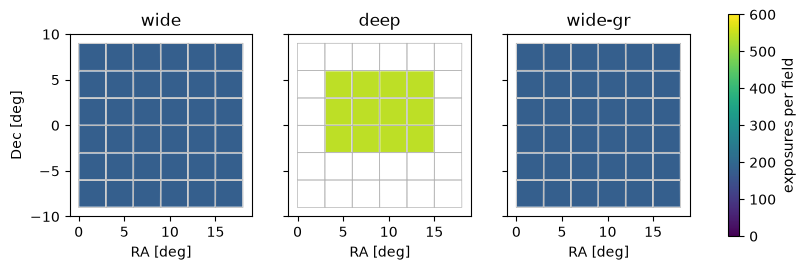

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3.6), sharey=True)
for ax, (name, survey) in zip(axes, surveys.items()):
    nexp = survey.get_fieldcoverage()
    observed = survey.fields.loc[nexp.index]
    observed.assign(nexp=nexp).plot(column="nexp", ax=ax, cmap="viridis", vmin=0, vmax=600,
                                    edgecolor="w", legend=False)
    survey.fields.boundary.plot(ax=ax, color="0.7", lw=0.5)
    ax.set(title=name, xlabel="RA [deg]", xlim=(-1, 19), ylim=(-10, 10), aspect="equal")
axes[0].set_ylabel("Dec [deg]")
fig.colorbar(axes[0].collections[0], ax=axes, label="exposures per field", shrink=0.8)

## Simulate one SN Ia population

All surveys must observe the *same* universe, so we draw a single SN Ia population covering the whole
footprint (RA $\in[0, 18]$, Dec $\in[-9, 9]$ deg) and the survey period. Starting 30 days before the survey
lets us include SNe that are already declining when observations begin. With `tstart` and `tstop` given,
the number of SNe follows from the volumetric rate.

In [7]:
snia = skysurvey.SNeIa.from_draw(tstart=MJD_START - 30, tstop=MJD_START + DURATION,
                                 zmax=1.0, radec={"ra_range": [0, 18], "dec_range": [-9, 9]})
print(f"{len(snia.data)} SNe Ia drawn")

9346 SNe Ia drawn


Now we "observe" this population with each survey. The `seed` argument makes the flux noise reproducible.

In [8]:
%%time
dsets = {name: skysurvey.DataSet.from_targets_and_survey(snia, survey, seed=1)
         for name, survey in surveys.items()}

CPU times: user 26.7 s, sys: 3.08 s, total: 29.8 s
Wall time: 30 s


## Define a well-sampled lightcurve

A lightcurve point is a *detection* when its signal-to-noise ratio is at least 5. We call a SN **well sampled**
if, within $[-20, +50]$ rest-frame days around peak, it has:

- at least 5 detections,
- detections in at least 2 bands (to measure a colour),
- at least 2 detections *before* peak (to constrain the rise and the time of maximum).

{meth}`skysurvey.DataSet.get_data` with `detection=True` and `phase_range` returns the detected points with their
rest-frame `phase`.

In [9]:
def get_stats(dset):
    det = dset.get_data(detection=True, phase_range=[-20, 50])
    by_target = det.groupby(level="index")
    stats = pd.DataFrame({"ndet": by_target.size(),
                          "nbands": by_target["band"].nunique(),
                          "npre": by_target["phase"].apply(lambda p: (p < 0).sum())})
    stats["well_sampled"] = (stats["ndet"] >= 5) & (stats["nbands"] >= 2) & (stats["npre"] >= 2)
    return stats.join(dset.targets.data["z"])

stats = {name: get_stats(dset) for name, dset in dsets.items()}
pd.DataFrame({name: {"observed": len(dsets[name].obs_index),
                     "detected (>=1 point)": len(s),
                     "well sampled": s["well_sampled"].sum()}
              for name, s in stats.items()}).T

,observed,detected (>=1 point),well sampled
wide,9343,2485,1479
deep,3130,1883,1181
wide-gr,9343,2288,1012


## Redshift reach

The number of SNe is only half the story: the deep survey finds fewer SNe, but further away.

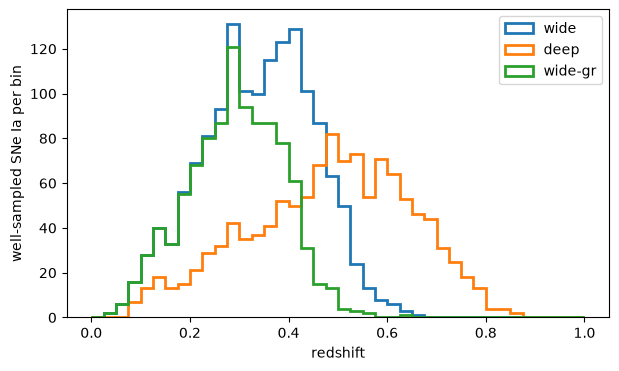

In [10]:
bins = np.linspace(0, 1.0, 41)
fig, ax = plt.subplots(figsize=(7, 4))
for name, s in stats.items():
    ax.hist(s.loc[s["well_sampled"], "z"], bins=bins, histtype="step", lw=2, label=name)
ax.set(xlabel="redshift", ylabel="well-sampled SNe Ia per bin")
ax.legend()

In [11]:
pd.DataFrame({name: s.loc[s["well_sampled"], "z"].quantile([0.5, 0.9]).round(3)
              for name, s in stats.items()}).T.rename(columns={0.5: "median z", 0.9: "90% z"})

,median z,90% z
wide,0.346,0.482
deep,0.495,0.691
wide-gr,0.295,0.414


## Lightcurve sampling

How many detections does a typical well-sampled SN get, and how many before peak? A faster cadence gives
more points per lightcurve, which helps to measure the lightcurve shape precisely.

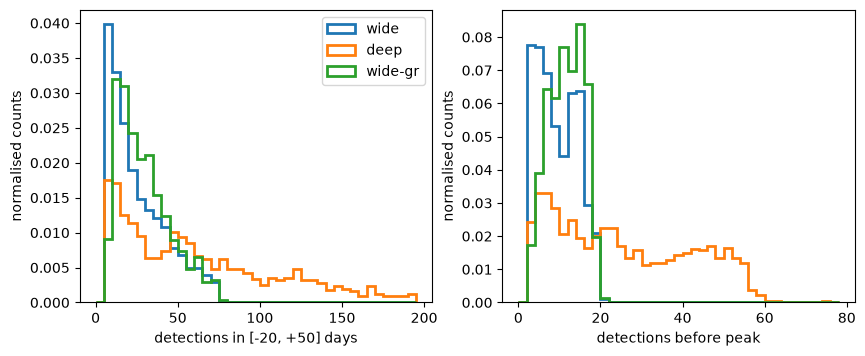

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for name, s in stats.items():
    good = s[s["well_sampled"]]
    axes[0].hist(good["ndet"], bins=np.arange(0, 200, 5), histtype="step", lw=2, density=True, label=name)
    axes[1].hist(good["npre"], bins=np.arange(0, 80, 2), histtype="step", lw=2, density=True, label=name)
axes[0].set(xlabel="detections in [-20, +50] days", ylabel="normalised counts")
axes[1].set(xlabel="detections before peak", ylabel="normalised counts")
axes[0].legend()

Let us look at one SN Ia, located in a central field so that all three strategies observed it.
The lines show the true lightcurve model and the dots the simulated observations, in $g$ (green), $r$ (red) and
$i$ (yellow). Note the missing $i$-band data for wide-gr.

Text(0.5, 1.02, 'SN Ia 77 at z=0.240')

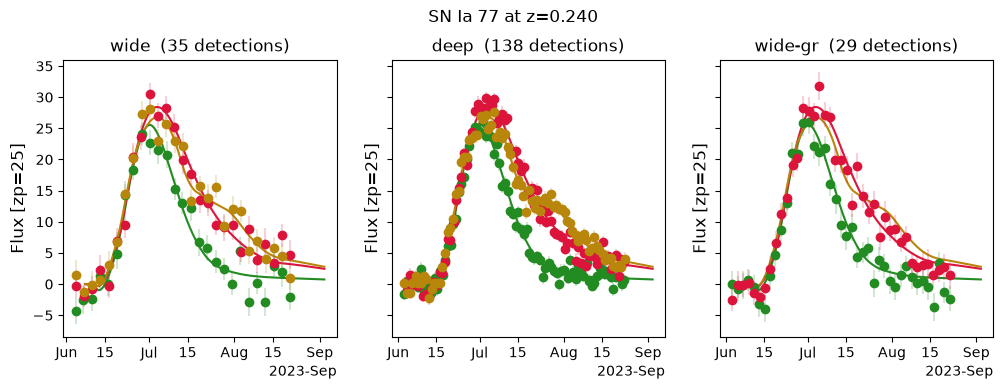

In [13]:
common = stats["wide"].index.intersection(stats["deep"].index).intersection(stats["wide-gr"].index)
candidates = stats["deep"].loc[common].query("well_sampled and 0.2 < z < 0.3")
index = candidates.index[0]

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), sharey=True)
for ax, (name, dset) in zip(axes, dsets.items()):
    dset.show_target_lightcurve(ax=ax, index=index, phase_window=[-30, 60], bands=gri)
    ax.set_title(f"{name}  ({stats[name].loc[index, 'ndet']} detections)")
fig.suptitle(f"SN Ia {index} at z={snia.data.loc[index, 'z']:.3f}", y=1.02)

## Does the answer depend on the transient class?

Yes. Type II supernovae (SNe II) are fainter than SNe Ia but more frequent, and they stay on a plateau for about
100 days. Let us repeat the exercise with {class}`skysurvey.SNeII`, limited to $z<0.3$ since they are too faint to be
seen further away.

In [14]:
%%time
snii = skysurvey.SNeII.from_draw(tstart=MJD_START - 30, tstop=MJD_START + DURATION,
                                 zmax=0.3, radec={"ra_range": [0, 18], "dec_range": [-9, 9]})
dsets_ii = {name: skysurvey.DataSet.from_targets_and_survey(snii, survey, seed=2)
            for name, survey in surveys.items()}
stats_ii = {name: get_stats(dset) for name, dset in dsets_ii.items()}
print(f"{len(snii.data)} SNe II drawn")

1695 SNe II drawn
CPU times: user 12.4 s, sys: 417 ms, total: 12.9 s
Wall time: 12.9 s


,SN Ia,SN II
wide,1479,764
deep,1181,408
wide-gr,1012,715


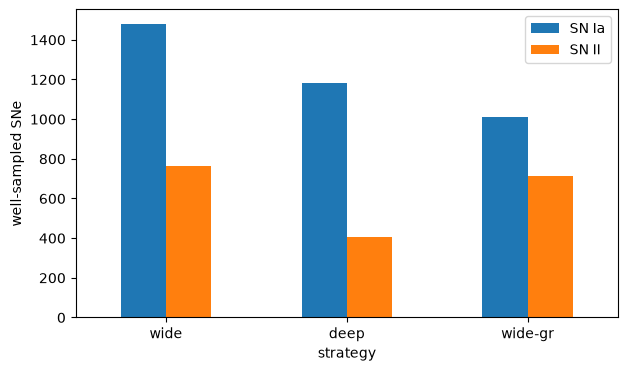

In [15]:
counts = pd.DataFrame({"SN Ia": {n: s["well_sampled"].sum() for n, s in stats.items()},
                       "SN II": {n: s["well_sampled"].sum() for n, s in stats_ii.items()}})

fig, ax = plt.subplots(figsize=(7, 4))
counts.plot.bar(ax=ax, rot=0)
ax.set(xlabel="strategy", ylabel="well-sampled SNe")
counts

## Take-away

With the same number of exposures:

- **wide** finds the largest number of well-sampled SNe: at low redshift the number of SNe grows with area, and a
  3-day cadence is enough to sample a SN Ia lightcurve that lasts weeks;
- **deep** finds fewer SNe, but reaches significantly higher redshift and gets many more points per lightcurve,
  ideal for precision lightcurve-shape measurements or high-redshift cosmology (remember that its deeper
  exposures would cost extra time in practice);
- **wide-gr** trades the $i$ band for a faster cadence, and loses: beyond $z\sim0.35$ the SN Ia light is
  redshifted out of $g$, so without $i$ fewer SNe pass the 2-band criterion. Colour coverage matters as much as cadence;
- the best strategy depends on the science case *and* on the transient class: SNe II are faint and nearby, so they
  benefit from area much more than from depth, and the deep strategy loses about half of them compared to wide
  (versus a much smaller loss for SNe Ia). Long-lived SNe II also hardly need $i$ or a fast cadence.

The criterion used here is simple; for a real survey design you would rather fit the lightcurves and apply
quality cuts on the fitted parameters.

## Next steps

- Learn more about the surveys in the [survey quickstart](../quickstart/quickstart_survey.ipynb).
- Explore other transient classes, e.g. [core-collapse supernovae](../transientclasses/sne_cc.ipynb).
- Change the transient rate with [this how-to](../howto/change_rate.ipynb).